# LungVision AI — Phase 7 Complete Recovery Run (512×512 FP32)

**Purpose:** safely continue `msd121_512_weighted_bce_direct` from the verified epoch-1 recovery checkpoint, preserve all artifacts, and produce a validation summary.

**Execution:** use Kaggle GPU (Tesla T4), attach the NIH Chest X-rays dataset and the `lungvisionresult` checkpoint/results dataset, then use **Run All**. The notebook stops at safe epoch boundaries after a 10-hour budget (leaving margin before Kaggle’s 12-hour session limit). If it stops partially, run it again in a fresh session; it resumes from the last checkpoint.

**Important:** this is an FP32 diagnostic continuation of an AMP-trained checkpoint, not an exact same-precision reproduction. It does not automatically evaluate the official test set. Test evaluation should happen only after model selection is frozen.


## 1. Environment, paths, and session controls

In [1]:
import os, gc, json, time, copy, random, hashlib, platform, warnings
from pathlib import Path
from dataclasses import asdict, dataclass

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import models, transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_recall_curve, roc_curve, confusion_matrix,
    brier_score_loss
)
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
LABELS = [
    "Cardiomegaly", "Edema", "Consolidation",
    "Pneumonia", "Atelectasis", "Pneumothorax"
]

NIH_ROOT = Path("/kaggle/input/datasets/nih-chest-xrays/data")

OUTPUT_DIR = Path("/kaggle/working/lungvision_phase7")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
RESULTS_DIR = OUTPUT_DIR / "results"
MANIFEST_DIR = OUTPUT_DIR / "manifests"
for p in [OUTPUT_DIR, CHECKPOINT_DIR, RESULTS_DIR, MANIFEST_DIR]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError(
        "CUDA GPU is required for this continuation notebook. "
        "In Kaggle Settings, select GPU (Tesla T4), restart the session, "
        "and rerun from the first cell."
    )

USE_AMP = False  # FP32 diagnostic continuation after non-finite FP16 forward logits.
VALIDATION_USE_AMP = False  # Keep validation in FP32.
NUM_WORKERS = 2
PIN_MEMORY = True

SMOKE_TEST = False
SMOKE_TRAIN_BATCHES = 2
SMOKE_EPOCHS = 1

FULL_EPOCHS = 5
PATIENCE = 3
# Stop cleanly at an epoch boundary before Kaggle's 12-hour session limit.
SESSION_BUDGET_HOURS = 10.0
SESSION_START_MONOTONIC = time.monotonic()
BATCH_SIZE_224 = 32
BATCH_SIZE_512 = 4  # Conservative for the multiscale 512x512 model on a T4.
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0
LOG_EVERY_TRAIN_BATCHES = 200
LOG_EVERY_VAL_BATCHES = 100

RUN_FULL_GRID = False  # This notebook runs ONE selected experiment per Kaggle session.

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything()
print("Device:", DEVICE, flush=True)
print("GPU:", torch.cuda.get_device_name(0), flush=True)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__, flush=True)
print("NIH_ROOT exists:", NIH_ROOT.exists(), flush=True)
print("AMP training:", USE_AMP, "| FP32 validation:", not VALIDATION_USE_AMP, flush=True)
assert SMOKE_TEST is False


Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
NIH_ROOT exists: True
AMP training: False | FP32 validation: True


In [2]:
# Preserved Kaggle output dataset (the path supplied by the user).
# Kaggle mounts attached datasets under /kaggle/input/<owner>/<dataset-slug>.
PRESERVED_DATASET_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/lungvisionresult"
)

# Some Kaggle environments mount as /kaggle/input/<dataset-slug> instead.
# Try the exact supplied path first, then a safe fallback search by dataset slug.
if not PRESERVED_DATASET_ROOT.exists():
    fallback = Path("/kaggle/input/lungvisionresult")
    if fallback.exists():
        PRESERVED_DATASET_ROOT = fallback

print("Preserved dataset path:", PRESERVED_DATASET_ROOT)
print("Path exists:", PRESERVED_DATASET_ROOT.exists())

# Accept either a folder containing lungvision_phase7/{checkpoints,results,manifests}
# or a folder that directly contains {checkpoints,results,manifests}.
if not PRESERVED_DATASET_ROOT.exists():
    raise FileNotFoundError(
        "Preserved output dataset was not found. Check the Kaggle input mount path "
        "and ensure the output dataset is attached to this notebook."
    )

import shutil
nested_root = PRESERVED_DATASET_ROOT / "lungvision_phase7"
if (nested_root / "checkpoints").exists():
    PRESERVED_ROOT = nested_root
elif (PRESERVED_DATASET_ROOT / "checkpoints").exists():
    PRESERVED_ROOT = PRESERVED_DATASET_ROOT
else:
    # Kaggle output datasets may retain a parent folder from the saved output.
    candidates = [p for p in PRESERVED_DATASET_ROOT.rglob("checkpoints") if p.is_dir()]
    if not candidates:
        raise FileNotFoundError(
            f"No checkpoints folder found inside {PRESERVED_DATASET_ROOT}. "
            "Inspect the attached Kaggle dataset structure."
        )
    PRESERVED_ROOT = candidates[0].parent

print("Resolved preserved output root:", PRESERVED_ROOT)
for folder in ["checkpoints", "results", "manifests"]:
    src = PRESERVED_ROOT / folder
    dst = OUTPUT_DIR / folder
    if src.exists():
        dst.mkdir(parents=True, exist_ok=True)
        copied = 0
        for item in src.iterdir():
            target = dst / item.name
            # Do not overwrite a newer resume checkpoint or an existing local file.
            if not target.exists():
                if item.is_file():
                    shutil.copy2(item, target)
                    copied += 1
        print(f"{folder}: copied {copied} new file(s); total available: {len(list(dst.iterdir()))}")
    else:
        print(f"{folder}: not present in preserved dataset")

print("Preserved checkpoint files:")
for item in sorted(CHECKPOINT_DIR.glob("*.pth")):
    print(" -", item.name)


Preserved dataset path: /kaggle/input/datasets/babulkumar07/lungvisionresult
Path exists: True
Resolved preserved output root: /kaggle/input/datasets/babulkumar07/lungvisionresult/results (1)/lungvision_phase7
checkpoints: copied 6 new file(s); total available: 6
results: copied 6 new file(s); total available: 6
manifests: copied 2 new file(s); total available: 2
Preserved checkpoint files:
 - msd121_224_focal_direct.pth
 - msd121_224_focal_letterbox.pth
 - msd121_224_weighted_bce_direct.pth
 - msd121_224_weighted_bce_letterbox.pth
 - msd121_512_weighted_bce_direct.pth
 - msd121_512_weighted_bce_direct_last.pth


**Preserved output source:** This notebook now imports checkpoints directly from the attached Kaggle dataset at `/kaggle/input/datasets/babulkumar07/lungvision-ai-disease-classification-result`. You do not need to upload or search for `results.zip` separately.

## 2. Reconstruct the exact NIH train/validation/test split

In [3]:
required_files = [
    NIH_ROOT / "Data_Entry_2017.csv",
    NIH_ROOT / "train_val_list.txt",
    NIH_ROOT / "test_list.txt"
]
missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(
        "NIH dataset files missing:\n" + "\n".join(missing) +
        "\nUpdate NIH_ROOT to the directory containing the three files."
    )

# Index image paths from NIH image folders.
image_map = {}
for folder in sorted(NIH_ROOT.glob("images_*")):
    image_dir = folder / "images"
    if image_dir.exists():
        for f in image_dir.iterdir():
            if f.suffix.lower() in {".png", ".jpg", ".jpeg"}:
                image_map[f.name] = str(f)

print("Indexed images:", len(image_map))

nih = pd.read_csv(NIH_ROOT / "Data_Entry_2017.csv")
official_train_val = set((NIH_ROOT / "train_val_list.txt").read_text().splitlines())
official_test = set((NIH_ROOT / "test_list.txt").read_text().splitlines())

nih = nih[nih["Image Index"].isin(official_train_val | official_test)].copy()
nih = nih[nih["View Position"].isin(["AP", "PA"])].copy()

for label in LABELS:
    nih[label] = nih["Finding Labels"].apply(
        lambda value: int(label in str(value).split("|"))
    )

nih["image_path"] = nih["Image Index"].map(image_map)
nih = nih.dropna(subset=["image_path"]).copy()
nih["patient_id"] = nih["Patient ID"].astype(str)
nih["split"] = np.where(nih["Image Index"].isin(official_test), "test", "train_pool")

# Exact procedure used in the supplied baseline notebook: patient-wise 15% validation split.
pool = nih[nih["split"] == "train_pool"].copy()
splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_idx, val_idx = next(splitter.split(pool, groups=pool["patient_id"]))
nih.loc[pool.index[train_idx], "split"] = "train"
nih.loc[pool.index[val_idx], "split"] = "validation"

train_df = nih[nih.split == "train"].copy().reset_index(drop=True)
val_df = nih[nih.split == "validation"].copy().reset_index(drop=True)
test_df = nih[nih.split == "test"].copy().reset_index(drop=True)

def verify_patient_disjointness(frames):
    names = list(frames)
    for i in range(len(names)):
        for j in range(i+1, len(names)):
            a = set(frames[names[i]]["patient_id"])
            b = set(frames[names[j]]["patient_id"])
            overlap = a & b
            print(f"{names[i]} vs {names[j]} patient overlap:", len(overlap))
            assert not overlap, f"Patient leakage between {names[i]} and {names[j]}"

verify_patient_disjointness({
    "train": train_df, "validation": val_df, "test": test_df
})

print("\nImages:", {"train":len(train_df), "validation":len(val_df), "test":len(test_df)})
print("Patients:", {k:v.patient_id.nunique() for k,v in {
    "train":train_df, "validation":val_df, "test":test_df
}.items()})
display(nih.groupby("split")[LABELS].sum().astype(int))

Indexed images: 112120
train vs validation patient overlap: 0
train vs test patient overlap: 0
validation vs test patient overlap: 0

Images: {'train': 73023, 'validation': 13501, 'test': 25596}
Patients: {'train': 23806, 'validation': 4202, 'test': 2797}


,Cardiomegaly,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax
split,,,,,,
test,1069,925,1815,555,3279,2665
train,1437,1169,2408,737,6935,2170
validation,270,209,444,139,1345,467


In [4]:
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

# Fingerprint ordered image IDs and split assignments. This proves which partition was used.
split_records = nih[["Image Index", "Patient ID", "split"]].sort_values(
    ["split", "Patient ID", "Image Index"]
)
split_payload = split_records.to_csv(index=False).encode("utf-8")
split_sha256 = hashlib.sha256(split_payload).hexdigest()

manifest_path = MANIFEST_DIR / "nih_phase7_split_manifest.csv"
nih.to_csv(manifest_path, index=False)

split_summary = {
    "seed": SEED,
    "split_method": "NIH official test list + GroupShuffleSplit(test_size=0.15, random_state=42) on official train_val pool",
    "view_filter": ["AP", "PA"],
    "labels": LABELS,
    "counts": {k: int((nih.split == k).sum()) for k in ["train","validation","test"]},
    "patient_counts": {k: int(nih.loc[nih.split == k, "patient_id"].nunique())
                       for k in ["train","validation","test"]},
    "split_sha256": split_sha256,
    "manifest_file": str(manifest_path),
    "nih_root": str(NIH_ROOT)
}
with open(MANIFEST_DIR / "split_summary.json", "w") as f:
    json.dump(split_summary, f, indent=2)

print(json.dumps(split_summary, indent=2))

{
  "seed": 42,
  "split_method": "NIH official test list + GroupShuffleSplit(test_size=0.15, random_state=42) on official train_val pool",
  "view_filter": [
    "AP",
    "PA"
  ],
  "labels": [
    "Cardiomegaly",
    "Edema",
    "Consolidation",
    "Pneumonia",
    "Atelectasis",
    "Pneumothorax"
  ],
  "counts": {
    "train": 73023,
    "validation": 13501,
    "test": 25596
  },
  "patient_counts": {
    "train": 23806,
    "validation": 4202,
    "test": 2797
  },
  "split_sha256": "ca0d2ed9efe6c4a2b479b25d5c10e762bdffcda1eeaf5672fcca499e6ddb7a09",
  "manifest_file": "/kaggle/working/lungvision_phase7/manifests/nih_phase7_split_manifest.csv",
  "nih_root": "/kaggle/input/datasets/nih-chest-xrays/data"
}


## 3. Preprocessing, dataset, and dataloaders

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..0.9882353720664978].


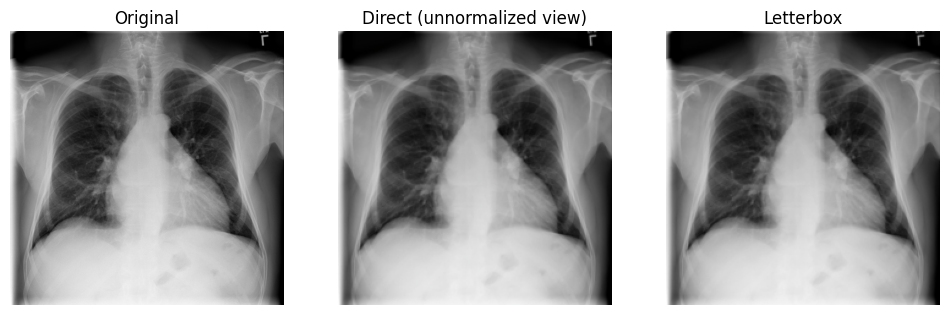

In [5]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

class Letterbox:
    def __init__(self, size, fill=(0,0,0)):
        self.size = int(size)
        self.fill = fill
    def __call__(self, image):
        image = image.convert("RGB")
        w, h = image.size
        scale = min(self.size / w, self.size / h)
        nw, nh = max(1, round(w*scale)), max(1, round(h*scale))
        image = image.resize((nw, nh), Image.Resampling.BILINEAR)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        left = (self.size - nw) // 2
        top = (self.size - nh) // 2
        canvas.paste(image, (left, top))
        return canvas

def build_transform(size, preprocessing):
    if preprocessing == "direct":
        geometry = transforms.Resize((size, size), interpolation=transforms.InterpolationMode.BILINEAR)
    elif preprocessing == "letterbox":
        geometry = Letterbox(size)
    else:
        raise ValueError(preprocessing)
    return transforms.Compose([
        geometry,
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])

class NIHXrayDataset(Dataset):
    def __init__(self, frame, size, preprocessing):
        self.frame = frame.reset_index(drop=True)
        self.transform = build_transform(size, preprocessing)
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row.image_path) as im:
            image = im.convert("RGB")
        image = self.transform(image)
        target = torch.tensor(row[LABELS].to_numpy(dtype=np.float32), dtype=torch.float32)
        return image, target

def make_loaders(size, preprocessing, batch_size):
    train_ds = NIHXrayDataset(train_df, size, preprocessing)
    val_ds = NIHXrayDataset(val_df, size, preprocessing)
    test_ds = NIHXrayDataset(test_df, size, preprocessing)
    common = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False, **common)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, **common)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, **common)
    return train_loader, val_loader, test_loader

# Visual sanity check: original, direct and letterboxed image.
sample_path = train_df.iloc[0].image_path
with Image.open(sample_path) as im:
    original = im.convert("RGB")
fig, axes = plt.subplots(1, 3, figsize=(12,4))
axes[0].imshow(original); axes[0].set_title("Original")
axes[1].imshow(build_transform(224, "direct")(original).permute(1,2,0).numpy()*np.array(IMAGENET_STD)+np.array(IMAGENET_MEAN)); axes[1].set_title("Direct (unnormalized view)")
axes[2].imshow(Letterbox(224)(original)); axes[2].set_title("Letterbox")
for ax in axes: ax.axis("off")
plt.show()

## 4. MultiScaleDenseNet121 architecture

In [6]:
class MultiScaleDenseNet121(nn.Module):
    def __init__(self, pretrained=True, dropout=0.25):
        super().__init__()
        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        base = models.densenet121(weights=weights)
        f = base.features

        # DenseNet121 feature stages: stem, dense block 1, transition 1,
        # dense block 2, transition 2, dense block 3, transition 3, dense block 4.
        self.stem = nn.Sequential(f.conv0, f.norm0, f.relu0, f.pool0)
        self.block1 = f.denseblock1
        self.trans1 = f.transition1
        self.block2 = f.denseblock2
        self.trans2 = f.transition2
        self.block3 = f.denseblock3
        self.trans3 = f.transition3
        self.block4 = f.denseblock4
        self.final_norm = f.norm5

        # DenseNet channels after stages: 256, 512, 1024; final: 1024.
        self.lat2 = nn.Conv2d(256, 128, kernel_size=1)
        self.lat3 = nn.Conv2d(512, 128, kernel_size=1)
        self.lat4 = nn.Conv2d(1024, 128, kernel_size=1)
        self.fuse = nn.Sequential(
            nn.Conv2d(128*3, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.dropout = nn.Dropout(dropout)
        # Decoupled disease heads: each disease has its own classifier.
        self.heads = nn.ModuleList([
            nn.Linear(512, 1) for _ in LABELS
        ])

    def forward(self, x):
        x = self.stem(x)
        p2 = self.block1(x)       # 256 channels
        x = self.trans1(p2)
        p3 = self.block2(x)       # 512 channels
        x = self.trans2(p3)
        p4 = self.block3(x)       # 1024 channels
        x = self.trans3(p4)
        x = self.block4(x)
        x = self.final_norm(x)
        # Keep P2/P3/P4 spatial maps aligned to P2 resolution.
        target_size = p2.shape[-2:]
        l2 = self.lat2(p2)
        l3 = F.interpolate(self.lat3(p3), size=target_size, mode="bilinear", align_corners=False)
        l4 = F.interpolate(self.lat4(p4), size=target_size, mode="bilinear", align_corners=False)
        fused = self.fuse(torch.cat([l2, l3, l4], dim=1))
        pooled = torch.cat([self.avg_pool(fused), self.max_pool(fused)], dim=1).flatten(1)
        pooled = self.dropout(pooled)
        return torch.cat([head(pooled) for head in self.heads], dim=1)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_check = MultiScaleDenseNet121(pretrained=False).to(DEVICE)
dummy = torch.randn(1, 3, 512, 512, device=DEVICE)
with torch.no_grad():
    out = model_check(dummy)
assert out.shape == (1, 6), out.shape
print("512x512 model smoke output:", out.shape, "| trainable parameters:", count_parameters(model_check), flush=True)
del model_check, dummy, out
gc.collect()
if DEVICE.type == "cuda": torch.cuda.empty_cache()

512x512 model smoke output: torch.Size([1, 6]) | trainable parameters: 8071942


## 5. Loss functions and experiment definitions

In [7]:
class MultiLabelFocalLoss(nn.Module):
    """Binary focal loss with per-class positive weighting."""
    def __init__(self, alpha_pos=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.register_buffer("alpha_pos", alpha_pos if alpha_pos is not None else torch.ones(len(LABELS)))
        self.gamma = gamma
        self.reduction = reduction
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1-probs) * (1-targets)
        focal_factor = (1-p_t).pow(self.gamma)
        # Apply class-specific positive weight to positive labels; negatives retain weight 1.
        pos_w = self.alpha_pos.view(1, -1)
        class_weight = targets * pos_w + (1-targets)
        loss = focal_factor * bce * class_weight
        if self.reduction == "sum": return loss.sum()
        if self.reduction == "none": return loss
        return loss.mean()

def compute_pos_weights(frame):
    pos = frame[LABELS].sum().to_numpy(dtype=np.float64)
    neg = len(frame) - pos
    weights = neg / np.maximum(pos, 1.0)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

POS_WEIGHTS = compute_pos_weights(train_df)
print("Train-only positive weights:", dict(zip(LABELS, POS_WEIGHTS.cpu().numpy().round(3))))

EXPERIMENTS = []
for size in [224, 512]:
    for loss_name in ["weighted_bce", "focal"]:
        for prep in ["direct", "letterbox"]:
            EXPERIMENTS.append({
                "experiment_id": f"msd121_{size}_{loss_name}_{prep}",
                "architecture": "MultiScaleDenseNet121",
                "image_size": size,
                "loss": loss_name,
                "preprocessing": prep,
                "seed": SEED
            })
display(pd.DataFrame(EXPERIMENTS))

Train-only positive weights: {'Cardiomegaly': np.float32(49.816), 'Edema': np.float32(61.466), 'Consolidation': np.float32(29.325), 'Pneumonia': np.float32(98.081), 'Atelectasis': np.float32(9.53), 'Pneumothorax': np.float32(32.651)}


,experiment_id,architecture,image_size,loss,preprocessing,seed
0,msd121_224_weighted_bce_direct,MultiScaleDenseNet121,224,weighted_bce,direct,42
1,msd121_224_weighted_bce_letterbox,MultiScaleDenseNet121,224,weighted_bce,letterbox,42
2,msd121_224_focal_direct,MultiScaleDenseNet121,224,focal,direct,42
3,msd121_224_focal_letterbox,MultiScaleDenseNet121,224,focal,letterbox,42
4,msd121_512_weighted_bce_direct,MultiScaleDenseNet121,512,weighted_bce,direct,42
5,msd121_512_weighted_bce_letterbox,MultiScaleDenseNet121,512,weighted_bce,letterbox,42
6,msd121_512_focal_direct,MultiScaleDenseNet121,512,focal,direct,42
7,msd121_512_focal_letterbox,MultiScaleDenseNet121,512,focal,letterbox,42


## 6. Numerically guarded training and validation utilities

In [8]:
def make_loss(loss_name):
    if loss_name == "weighted_bce":
        return nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHTS)
    if loss_name == "focal":
        return MultiLabelFocalLoss(alpha_pos=POS_WEIGHTS, gamma=2.0)
    raise ValueError(f"Unknown loss: {loss_name}")


def safe_auc(y_true, y_prob):
    """Strict AUROC: fail with diagnostics instead of silently masking NaNs."""
    y_true = np.asarray(y_true, dtype=np.float32)
    y_prob = np.asarray(y_prob, dtype=np.float32)

    if y_true.ndim != 2 or y_prob.ndim != 2:
        raise ValueError(f"Expected 2D arrays; got y_true={y_true.shape}, y_prob={y_prob.shape}")
    if y_true.shape != y_prob.shape:
        raise ValueError(f"Target/prediction shape mismatch: {y_true.shape} vs {y_prob.shape}")

    bad_y = ~np.isfinite(y_true)
    bad_p = ~np.isfinite(y_prob)
    if bad_y.any():
        raise FloatingPointError(
            f"Validation targets contain non-finite values: total={int(bad_y.sum())}, "
            f"per_class={bad_y.sum(axis=0).tolist()}"
        )
    if bad_p.any():
        raise FloatingPointError(
            f"Validation probabilities contain non-finite values: total={int(bad_p.sum())}, "
            f"per_class={bad_p.sum(axis=0).tolist()}; inspect model logits/weights."
        )

    vals = []
    for j in range(y_true.shape[1]):
        if len(np.unique(y_true[:, j])) < 2:
            vals.append(np.nan)
        else:
            vals.append(roc_auc_score(y_true[:, j], y_prob[:, j]))
    if not np.isfinite(np.asarray(vals, dtype=float)).any():
        raise ValueError("AUROC is undefined for every class in this validation set.")
    return np.asarray(vals, dtype=float)


@torch.inference_mode()
def evaluate_loss_and_predictions(model, loader, criterion, log_every=LOG_EVERY_VAL_BATCHES):
    """
    Validation runs in FP32, independently of AMP training.
    This both improves numerical stability and makes non-finite outputs diagnosable.
    """
    model.eval()
    losses, ys, ps = [], [], []
    total_batches = len(loader)

    for batch_i, (x, y) in enumerate(loader):
        x = x.to(DEVICE, non_blocking=True, dtype=torch.float32)
        y = y.to(DEVICE, non_blocking=True, dtype=torch.float32)

        # Deliberately no autocast in validation.
        logits = model(x.float())
        if not torch.isfinite(logits).all():
            bad = (~torch.isfinite(logits)).sum(dim=0).detach().cpu().tolist()
            raise FloatingPointError(
                f"Non-finite validation logits at batch {batch_i + 1}/{total_batches}; "
                f"bad values per output={bad}. Model parameters may have diverged."
            )

        loss = criterion(logits.float(), y.float())
        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite validation loss at batch {batch_i + 1}/{total_batches}."
            )

        probs = torch.sigmoid(logits.float())
        if not torch.isfinite(probs).all():
            raise FloatingPointError(
                f"Non-finite sigmoid probabilities at validation batch {batch_i + 1}."
            )

        losses.append(float(loss.item()) * len(x))
        ys.append(y.cpu().numpy())
        ps.append(probs.cpu().numpy())

        if (batch_i + 1) % log_every == 0 or (batch_i + 1) == total_batches:
            print(
                f"  validation batches: {batch_i + 1}/{total_batches}",
                flush=True
            )

    y_true = np.concatenate(ys, axis=0)
    y_prob = np.concatenate(ps, axis=0)
    auc = safe_auc(y_true, y_prob)

    ap = []
    for j in range(len(LABELS)):
        if len(np.unique(y_true[:, j])) > 1:
            ap.append(average_precision_score(y_true[:, j], y_prob[:, j]))
        else:
            ap.append(np.nan)

    val_loss = float(sum(losses) / max(len(loader.dataset), 1))
    return val_loss, y_true, y_prob, auc, np.asarray(ap, dtype=float)


print("Numerically guarded metrics and FP32 validation utilities are ready.", flush=True)


Numerically guarded metrics and FP32 validation utilities are ready.


## 7. Verify preserved checkpoints

Run this after the split, model, and loss cells. The code checks checkpoint metadata against the recreated split fingerprint and expected experiment ID. It does not treat a missing history CSV as a missing model checkpoint.

In [9]:
def verify_preserved_checkpoints():
    rows = []
    for cfg in EXPERIMENTS:
        ckpt_path = CHECKPOINT_DIR / f'{cfg["experiment_id"]}.pth'
        hist_path = RESULTS_DIR / f'{cfg["experiment_id"]}_history.csv'
        row = {
            "experiment_id": cfg["experiment_id"],
            "checkpoint_exists": ckpt_path.exists(),
            "history_exists": hist_path.exists(),
            "checkpoint_valid": False,
            "best_val_macro_auroc": np.nan,
            "best_epoch": np.nan,
            "note": ""
        }
        if ckpt_path.exists():
            try:
                ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
                if ckpt.get("split_sha256") != split_sha256:
                    raise ValueError("split fingerprint mismatch")
                if ckpt.get("config", {}).get("experiment_id") != cfg["experiment_id"]:
                    raise ValueError("experiment ID mismatch")
                row["checkpoint_valid"] = True
                row["best_val_macro_auroc"] = ckpt.get("best_val_macro_auroc", np.nan)
                row["best_epoch"] = ckpt.get("epoch", np.nan)
                row["note"] = "validated"
            except Exception as exc:
                row["note"] = f"INVALID: {exc}"
        else:
            row["note"] = "checkpoint absent"
        rows.append(row)
    report = pd.DataFrame(rows)
    display(report)
    report.to_csv(RESULTS_DIR / "preserved_checkpoint_audit.csv", index=False)
    return report

checkpoint_audit = verify_preserved_checkpoints()

,experiment_id,checkpoint_exists,history_exists,checkpoint_valid,best_val_macro_auroc,best_epoch,note
0,msd121_224_weighted_bce_direct,True,True,True,0.819726,4.0,validated
1,msd121_224_weighted_bce_letterbox,True,True,True,0.818934,4.0,validated
2,msd121_224_focal_direct,True,True,True,0.814352,5.0,validated
3,msd121_224_focal_letterbox,True,False,True,0.798783,2.0,validated
4,msd121_512_weighted_bce_direct,True,True,True,0.705080,1.0,validated
5,msd121_512_weighted_bce_letterbox,False,False,False,NaN,NaN,checkpoint absent
6,msd121_512_focal_direct,False,False,False,NaN,NaN,checkpoint absent
7,msd121_512_focal_letterbox,False,False,False,NaN,NaN,checkpoint absent


## 8. Resumable training implementation

Training checkpoints are written atomically. A pre-epoch state protects against a session stopping mid-epoch; a second state is saved after training and before validation so an interrupted validation phase can resume without repeating training.

In [10]:
def atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = Path(str(path) + ".tmp")
    torch.save(payload, tmp_path)
    os.replace(tmp_path, path)


def save_training_state(
    path, model, optimizer, scaler, scheduler,
    next_epoch, current_epoch, phase,
    best_auc, best_epoch, bad_epochs, history, cfg,
    current_train_loss=np.nan
):
    payload = {
        "next_epoch": int(next_epoch),
        "current_epoch": int(current_epoch),
        "phase": str(phase),  # "train" or "validate"
        "current_train_loss": float(current_train_loss) if np.isfinite(current_train_loss) else None,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_auc": float(best_auc),
        "best_epoch": int(best_epoch),
        "bad_epochs": int(bad_epochs),
        "history": history,
        "config": cfg,
        "split_sha256": split_sha256,
        "labels": LABELS,
        "torch_version": torch.__version__,
        "image_size": cfg["image_size"],
        "preprocessing": cfg["preprocessing"],
        "saved_at_unix": time.time(),
    }
    atomic_torch_save(payload, path)


def _save_best_checkpoint(path, model, cfg, best_auc, epoch):
    payload = {
        "model_state_dict": copy.deepcopy(model.state_dict()),
        "config": cfg,
        "best_val_macro_auroc": float(best_auc),
        "epoch": int(epoch),
        "labels": LABELS,
        "split_sha256": split_sha256,
        "torch_version": torch.__version__,
        "preprocessing": cfg["preprocessing"],
        "image_size": int(cfg["image_size"]),
    }
    atomic_torch_save(payload, path)


def train_one_experiment_resumable(cfg):
    seed_everything(cfg["seed"])
    size = int(cfg["image_size"])
    batch_size = BATCH_SIZE_224 if size == 224 else BATCH_SIZE_512
    train_loader, val_loader, _ = make_loaders(size, cfg["preprocessing"], batch_size)

    exp_id = cfg["experiment_id"]
    best_path = CHECKPOINT_DIR / f"{exp_id}.pth"
    last_path = CHECKPOINT_DIR / f"{exp_id}_last.pth"
    history_path = RESULTS_DIR / f"{exp_id}_history.csv"

    resume_exists = last_path.exists()
    model = MultiScaleDenseNet121(pretrained=not resume_exists).to(DEVICE)
    criterion = make_loss(cfg["loss"])
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=1
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    start_epoch = 0
    resume_phase = "train"
    resume_current_epoch = 0
    best_auc, best_epoch, bad_epochs, history = -np.inf, 0, 0, []
    resumed_train_loss = None

    if resume_exists:
        state = torch.load(last_path, map_location=DEVICE, weights_only=False)
        if state.get("split_sha256") != split_sha256:
            raise ValueError("Resume checkpoint split fingerprint mismatch.")
        if state.get("config", {}).get("experiment_id") != exp_id:
            raise ValueError("Resume checkpoint belongs to another experiment.")
        if state.get("labels") != LABELS:
            raise ValueError("Resume checkpoint label order mismatch.")

        model.load_state_dict(state["model_state_dict"])
        optimizer.load_state_dict(state["optimizer_state_dict"])
        # This diagnostic continuation intentionally disables AMP. Do not restore
        # the old FP16 GradScaler state into a disabled scaler.
        if scaler.is_enabled():
            scaler_state = state.get("scaler_state_dict", {})
            if scaler_state:
                scaler.load_state_dict(scaler_state)
        else:
            print("FP32 diagnostic: AMP disabled; saved FP16 GradScaler state not restored.", flush=True)
        scheduler.load_state_dict(state["scheduler_state_dict"])
        start_epoch = int(state["next_epoch"])
        resume_phase = str(state.get("phase", "train"))
        resume_current_epoch = int(state.get("current_epoch", start_epoch))
        best_auc = float(state["best_auc"])
        best_epoch = int(state["best_epoch"])
        bad_epochs = int(state["bad_epochs"])
        history = list(state.get("history", []))
        resumed_train_loss = state.get("current_train_loss", None)

        print(
            f"RESUMING {exp_id}: next_epoch={start_epoch + 1}, "
            f"saved_phase={resume_phase}, current_epoch={resume_current_epoch + 1}",
            flush=True
        )
    elif best_path.exists():
        raise RuntimeError(
            f"{best_path.name} exists but {last_path.name} does not. "
            "This is a best-weights-only checkpoint, not an exact-resume checkpoint. "
            "It will not be overwritten. Move it aside only if you explicitly intend "
            "to restart this experiment from ImageNet initialization."
        )
    else:
        print(f"Starting new experiment: {exp_id}", flush=True)

    if start_epoch >= FULL_EPOCHS or bad_epochs >= PATIENCE:
        print("No training required: epoch or early-stopping limit already reached.", flush=True)

    for epoch in range(start_epoch, FULL_EPOCHS):
        if bad_epochs >= PATIENCE:
            break
        elapsed_session = time.monotonic() - SESSION_START_MONOTONIC
        budget_seconds = SESSION_BUDGET_HOURS * 3600
        if elapsed_session >= budget_seconds:
            print(
                f"SESSION BUDGET REACHED ({elapsed_session/3600:.2f}h). "
                "Stopping at an epoch boundary; the last checkpoint is resumable.",
                flush=True
            )
            break

        # If a session stopped after the train phase but during validation,
        # resume validation without repeating the completed training epoch.
        resume_validation = (
            epoch == start_epoch
            and resume_phase == "validate"
            and resume_current_epoch == epoch
        )

        if not resume_validation:
            # This is a safe pre-epoch recovery point. If the session dies mid-epoch,
            # the same epoch is retrained from this checkpoint next session.
            save_training_state(
                last_path, model, optimizer, scaler, scheduler,
                next_epoch=epoch, current_epoch=epoch, phase="train",
                best_auc=best_auc, best_epoch=best_epoch,
                bad_epochs=bad_epochs, history=history, cfg=cfg
            )

            model.train()
            running_loss, seen = 0.0, 0
            consecutive_overflows = 0
            epoch_start = time.time()
            total_batches = len(train_loader)

            for batch_i, (x, y) in enumerate(train_loader):
                x = x.to(DEVICE, non_blocking=True, dtype=torch.float32)
                y = y.to(DEVICE, non_blocking=True, dtype=torch.float32)
                optimizer.zero_grad(set_to_none=True)

                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                    logits = model(x)
                    loss = criterion(logits, y)

                if not torch.isfinite(logits).all():
                    raise FloatingPointError(
                        f"Non-finite training logits in {exp_id}, "
                        f"epoch {epoch + 1}, batch {batch_i + 1}."
                    )
                if not torch.isfinite(loss):
                    raise FloatingPointError(
                        f"Non-finite training loss in {exp_id}, "
                        f"epoch {epoch + 1}, batch {batch_i + 1}."
                    )

                # Backpropagate scaled loss, then unscale before inspecting gradients.
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                grad_tensors = [
                    p.grad for p in model.parameters() if p.grad is not None
                ]

                # Check all gradients on-device and synchronize only once.
                if grad_tensors:
                    nonfinite_flags = torch.stack([
                        (~torch.isfinite(g)).any() for g in grad_tensors
                    ])
                    has_nonfinite_grad = bool(nonfinite_flags.any().item())
                else:
                    has_nonfinite_grad = True

                if has_nonfinite_grad:
                    if not scaler.is_enabled():
                        optimizer.zero_grad(set_to_none=True)
                        raise FloatingPointError(
                            f"Non-finite gradients with AMP disabled in {exp_id}, "
                            f"epoch {epoch + 1}, batch {batch_i + 1}."
                        )

                    # unscale_ has recorded the overflow; scaler.step skips this
                    # optimizer update and scaler.update lowers the scale.
                    old_scale = scaler.get_scale()
                    scaler.step(optimizer)
                    scaler.update()
                    new_scale = scaler.get_scale()
                    optimizer.zero_grad(set_to_none=True)

                    consecutive_overflows += 1
                    print(
                        f"AMP OVERFLOW | {exp_id} | epoch {epoch + 1} "
                        f"batch {batch_i + 1}/{total_batches} | "
                        f"scale {old_scale:g}->{new_scale:g} | "
                        f"consecutive={consecutive_overflows}",
                        flush=True
                    )

                    # Count the observed batch loss, but no optimizer update occurred.
                    running_loss += float(loss.detach().item()) * len(x)
                    seen += len(x)

                    if consecutive_overflows >= 20:
                        raise FloatingPointError(
                            f"20 consecutive AMP overflows in {exp_id}. "
                            "Stop and investigate numerical instability."
                        )
                    continue

                consecutive_overflows = 0

                grad_norm = nn.utils.clip_grad_norm_(
                    model.parameters(), GRAD_CLIP, error_if_nonfinite=True
                )
                if not torch.isfinite(grad_norm):
                    optimizer.zero_grad(set_to_none=True)
                    raise FloatingPointError(
                        f"Non-finite gradient norm after finite-gradient check in "
                        f"{exp_id}, epoch {epoch + 1}, batch {batch_i + 1}."
                    )

                scaler.step(optimizer)
                scaler.update()

                running_loss += float(loss.detach().item()) * len(x)
                seen += len(x)

                if (batch_i + 1) % LOG_EVERY_TRAIN_BATCHES == 0 or (batch_i + 1) == total_batches:
                    elapsed = time.time() - epoch_start
                    rate = seen / max(elapsed, 1e-6)
                    remaining = (len(train_loader.dataset) - seen) / max(rate, 1e-6)
                    print(
                        f"{exp_id} | epoch {epoch + 1}/{FULL_EPOCHS} | "
                        f"train batch {batch_i + 1}/{total_batches} | "
                        f"images {seen}/{len(train_loader.dataset)} | "
                        f"loss={running_loss / max(seen, 1):.4f} | "
                        f"ETA={remaining / 60:.1f} min",
                        flush=True
                    )

            if seen != len(train_loader.dataset):
                raise RuntimeError(
                    f"Training epoch saw {seen} images, expected {len(train_loader.dataset)}."
                )

            # Persist the trained model BEFORE validation. If validation is interrupted,
            # the next session resumes at validation instead of repeating this epoch.
            save_training_state(
                last_path, model, optimizer, scaler, scheduler,
                next_epoch=epoch, current_epoch=epoch, phase="validate",
                best_auc=best_auc, best_epoch=best_epoch,
                bad_epochs=bad_epochs, history=history, cfg=cfg,
                current_train_loss=running_loss / max(seen, 1)
            )
            resumed_train_loss = running_loss / max(seen, 1)
        else:
            print(
                f"Resuming validation for {exp_id}, epoch {epoch + 1}/{FULL_EPOCHS}",
                flush=True
            )

        val_start = time.time()
        val_loss, y_true, y_prob, aucs, aps = evaluate_loss_and_predictions(
            model, val_loader, criterion
        )
        macro_auc = float(np.nanmean(aucs))
        macro_ap = float(np.nanmean(aps))
        if not np.isfinite(macro_auc):
            raise FloatingPointError("Validation macro AUROC is non-finite.")

        scheduler.step(macro_auc)
        row = {
            "epoch": epoch + 1,
            "train_loss": (running_loss / max(seen, 1)) if not resume_validation else (
                resumed_train_loss if resumed_train_loss is not None else np.nan
            ),
            "val_loss": val_loss,
            "val_macro_auroc": macro_auc,
            "val_macro_auprc": macro_ap,
            "lr": optimizer.param_groups[0]["lr"],
            "epoch_seconds": time.time() - epoch_start if not resume_validation else np.nan,
            "validation_seconds": time.time() - val_start,
            "smoke_test": False
        }

        # Avoid duplicate epoch records if resuming at validation phase.
        history = [h for h in history if int(h.get("epoch", -1)) != epoch + 1]
        history.append(row)
        history.sort(key=lambda item: int(item["epoch"]))
        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"{exp_id} | epoch {epoch + 1}/{FULL_EPOCHS} COMPLETE | "
            f"train={row['train_loss']:.4f} val={val_loss:.4f} "
            f"AUROC={macro_auc:.4f} AUPRC={macro_ap:.4f}",
            flush=True
        )

        if macro_auc > best_auc:
            best_auc, best_epoch, bad_epochs = macro_auc, epoch + 1, 0
            _save_best_checkpoint(best_path, model, cfg, best_auc, best_epoch)
            print(f"New best checkpoint saved: {best_path}", flush=True)
        else:
            bad_epochs += 1

        # Epoch fully completed: next restart starts at the following epoch.
        save_training_state(
            last_path, model, optimizer, scaler, scheduler,
            next_epoch=epoch + 1, current_epoch=epoch, phase="train",
            best_auc=best_auc, best_epoch=best_epoch,
            bad_epochs=bad_epochs, history=history, cfg=cfg,
            current_train_loss=row["train_loss"]
        )

        if bad_epochs >= PATIENCE:
            print("Early stopping triggered.", flush=True)
            break

        # Do not carry stale validation-resume state into the next epoch.
        resume_phase = "train"

    status = "COMPLETED" if (
        (history and int(history[-1]["epoch"]) >= FULL_EPOCHS)
        or bad_epochs >= PATIENCE
    ) else "PARTIAL"

    elapsed_hours = (time.monotonic() - SESSION_START_MONOTONIC) / 3600
    result = {
        "experiment_id": exp_id,
        "status": status,
        "session_elapsed_hours": round(elapsed_hours, 3),
        "session_budget_hours": SESSION_BUDGET_HOURS,
        "best_val_macro_auroc": best_auc,
        "best_epoch": best_epoch,
        "epochs_completed": len(history),
        "checkpoint": str(best_path),
        "last_checkpoint": str(last_path),
        "history": str(history_path)
    }
    print("EXPERIMENT RESULT:", json.dumps(result, indent=2), flush=True)

    del model, optimizer, train_loader, val_loader
    gc.collect()
    torch.cuda.empty_cache()
    return result


print("Resumable trainer ready: atomic epoch checkpoints, validation-phase resume, "
      "FP32 validation, finite-value guards, and periodic progress logs.", flush=True)


Resumable trainer ready: atomic epoch checkpoints, validation-phase resume, FP32 validation, finite-value guards, and periodic progress logs.


## 9. Run one selected experiment in this Kaggle session

In [11]:
# Run ONE experiment per Kaggle session.
# Keep this ID unchanged if the session is interrupted; the notebook resumes it.
RUN_EXPERIMENT_ID = "msd121_512_weighted_bce_direct"

cfg_lookup = {cfg["experiment_id"]: cfg for cfg in EXPERIMENTS}
if RUN_EXPERIMENT_ID not in cfg_lookup:
    raise ValueError(f"Unknown experiment ID: {RUN_EXPERIMENT_ID}")

selected_cfg = cfg_lookup[RUN_EXPERIMENT_ID]
selected_ckpt = CHECKPOINT_DIR / f"{RUN_EXPERIMENT_ID}.pth"
selected_last = CHECKPOINT_DIR / f"{RUN_EXPERIMENT_ID}_last.pth"

if selected_ckpt.exists() and not selected_last.exists():
    print(
        "A best-weights checkpoint exists without a resume-state checkpoint. "
        "Training will NOT overwrite it. Inspect the checkpoint audit first.",
        flush=True
    )
elif selected_last.exists():
    print("Resume state found. Continuing from the last saved phase.", flush=True)
    # Preserve immutable copies of the supplied recovery artifacts before the
    # trainer writes a new working checkpoint.
    BACKUP_DIR = OUTPUT_DIR / "recovery_backups"
    BACKUP_DIR.mkdir(parents=True, exist_ok=True)
    import shutil
    for source_path in [selected_last, selected_ckpt]:
        if source_path.exists():
            backup_path = BACKUP_DIR / source_path.name
            if not backup_path.exists():
                shutil.copy2(source_path, backup_path)
                print("Preserved original checkpoint:", backup_path, flush=True)
    selected_result = train_one_experiment_resumable(selected_cfg)
else:
    print("No checkpoint for this experiment. Starting it from ImageNet weights.", flush=True)
    # Preserve immutable copies of the supplied recovery artifacts before the
    # trainer writes a new working checkpoint.
    BACKUP_DIR = OUTPUT_DIR / "recovery_backups"
    BACKUP_DIR.mkdir(parents=True, exist_ok=True)
    import shutil
    for source_path in [selected_last, selected_ckpt]:
        if source_path.exists():
            backup_path = BACKUP_DIR / source_path.name
            if not backup_path.exists():
                shutil.copy2(source_path, backup_path)
                print("Preserved original checkpoint:", backup_path, flush=True)
    selected_result = train_one_experiment_resumable(selected_cfg)


Resume state found. Continuing from the last saved phase.
Preserved original checkpoint: /kaggle/working/lungvision_phase7/recovery_backups/msd121_512_weighted_bce_direct_last.pth
Preserved original checkpoint: /kaggle/working/lungvision_phase7/recovery_backups/msd121_512_weighted_bce_direct.pth
FP32 diagnostic: AMP disabled; saved FP16 GradScaler state not restored.
RESUMING msd121_512_weighted_bce_direct: next_epoch=2, saved_phase=train, current_epoch=2
msd121_512_weighted_bce_direct | epoch 2/5 | train batch 200/18256 | images 800/73023 | loss=2.8619 | ETA=115.5 min
msd121_512_weighted_bce_direct | epoch 2/5 | train batch 400/18256 | images 1600/73023 | loss=3.1902 | ETA=114.7 min
msd121_512_weighted_bce_direct | epoch 2/5 | train batch 600/18256 | images 2400/73023 | loss=3.1910 | ETA=113.5 min
msd121_512_weighted_bce_direct | epoch 2/5 | train batch 800/18256 | images 3200/73023 | loss=3.0782 | ETA=112.3 min
msd121_512_weighted_bce_direct | epoch 2/5 | train batch 1000/18256 | ima

## 10. Validation-only comparison and artifact inventory

In [12]:
def build_validation_experiment_summary():
    rows = []
    for cfg in EXPERIMENTS:
        exp_id = cfg["experiment_id"]
        ckpt_path = CHECKPOINT_DIR / f"{exp_id}.pth"
        hist_path = RESULTS_DIR / f"{exp_id}_history.csv"
        row = {
            "experiment_id": exp_id,
            "image_size": cfg["image_size"],
            "loss": cfg["loss"],
            "preprocessing": cfg["preprocessing"],
            "checkpoint_exists": ckpt_path.exists(),
            "history_exists": hist_path.exists(),
            "best_val_macro_auroc": np.nan,
            "best_epoch": np.nan,
            "epochs_in_history": 0
        }
        if ckpt_path.exists():
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
            if ckpt.get("split_sha256") == split_sha256:
                row["best_val_macro_auroc"] = ckpt.get("best_val_macro_auroc", np.nan)
                row["best_epoch"] = ckpt.get("epoch", np.nan)
        if hist_path.exists():
            hist = pd.read_csv(hist_path)
            row["epochs_in_history"] = len(hist)
            if len(hist):
                row["history_best_val_macro_auroc"] = hist["val_macro_auroc"].max()
        rows.append(row)
    summary = pd.DataFrame(rows).sort_values(
        ["best_val_macro_auroc"], ascending=False, na_position="last"
    )
    display(summary)
    summary.to_csv(RESULTS_DIR / "phase7_validation_summary.csv", index=False)
    return summary

phase7_summary = build_validation_experiment_summary()

print("\nCheckpoint files:")
for p in sorted(CHECKPOINT_DIR.glob("*.pth")):
    print(p.name, f"{p.stat().st_size / (1024**2):.1f} MiB")

print("\nResult files:")
for p in sorted(RESULTS_DIR.iterdir()):
    print(p.name)

,experiment_id,image_size,loss,preprocessing,checkpoint_exists,history_exists,best_val_macro_auroc,best_epoch,epochs_in_history,history_best_val_macro_auroc
0,msd121_224_weighted_bce_direct,224,weighted_bce,direct,True,True,0.819726,4.0,7,0.819726
1,msd121_224_weighted_bce_letterbox,224,weighted_bce,letterbox,True,True,0.818934,4.0,7,0.818934
2,msd121_224_focal_direct,224,focal,direct,True,True,0.814352,5.0,8,0.814352
3,msd121_224_focal_letterbox,224,focal,letterbox,True,False,0.798783,2.0,0,NaN
4,msd121_512_weighted_bce_direct,512,weighted_bce,direct,True,True,0.778568,4.0,5,0.778568
5,msd121_512_weighted_bce_letterbox,512,weighted_bce,letterbox,False,False,NaN,NaN,0,NaN
6,msd121_512_focal_direct,512,focal,direct,False,False,NaN,NaN,0,NaN
7,msd121_512_focal_letterbox,512,focal,letterbox,False,False,NaN,NaN,0,NaN



Checkpoint files:
msd121_224_focal_direct.pth 31.4 MiB
msd121_224_focal_letterbox.pth 31.4 MiB
msd121_224_weighted_bce_direct.pth 31.4 MiB
msd121_224_weighted_bce_letterbox.pth 31.4 MiB
msd121_512_weighted_bce_direct.pth 31.4 MiB
msd121_512_weighted_bce_direct_last.pth 72.7 MiB

Result files:
msd121_224_focal_direct_history.csv
msd121_224_weighted_bce_direct_history.csv
msd121_224_weighted_bce_letterbox_history.csv
msd121_512_weighted_bce_direct_history.csv
phase7_validation_summary.csv
preserved_checkpoint_audit.csv
training_runs.csv


## 11. Session-by-session execution plan

1. Attach the NIH dataset and preserved output dataset as Kaggle inputs.
2. Confirm Kaggle Settings → Accelerator → GPU (Tesla T4).
3. Run cells from the top. The notebook will stop immediately if CUDA is unavailable.
4. Keep `RUN_EXPERIMENT_ID = "msd121_512_weighted_bce_direct"` for this first continuation.
5. If Kaggle stops, attach the newly preserved output dataset in the next session, keep the same experiment ID, and rerun. The `_last.pth` file records whether the next action is training or validation.
6. After the first experiment completes, change the ID to the next 512 configuration:
   - `msd121_512_weighted_bce_letterbox`
   - `msd121_512_focal_direct`
   - `msd121_512_focal_letterbox`
7. Keep the four imported 224×224 checkpoints unchanged.
8. Preserve `/kaggle/working/lungvision_phase7` as a Kaggle output after each session.

**Numerical note:** Validation is deliberately performed in FP32, while training uses CUDA AMP. Non-finite logits, loss, gradients, targets, or probabilities raise explicit errors. They are never silently replaced with zeros.

**Checkpoint note:** If a run is interrupted mid-training epoch, it restarts that epoch from the pre-epoch recovery state. If interrupted after the epoch's training phase, it resumes directly at validation. Exact mid-batch dataloader-position recovery is not implemented.


## 12. Final test evaluation — only after model selection is frozen

The official NIH test set must remain untouched during experiment selection. Run the code below only after choosing the final model(s) using validation metrics.

In [13]:
def load_experiment_model(cfg, checkpoint_path):
    model = MultiScaleDenseNet121(pretrained=False).to(DEVICE)
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    if checkpoint.get("split_sha256") != split_sha256:
        raise ValueError("Checkpoint split fingerprint differs from current manifest.")
    if checkpoint.get("config", {}).get("experiment_id") != cfg["experiment_id"]:
        raise ValueError("Checkpoint/config mismatch.")
    model.load_state_dict(checkpoint["model_state_dict"])
    return model, checkpoint

def evaluate_final_test(cfg):
    ckpt = CHECKPOINT_DIR / f'{cfg["experiment_id"]}.pth'
    if not ckpt.exists():
        raise FileNotFoundError(ckpt)
    model, checkpoint = load_experiment_model(cfg, ckpt)
    batch_size = BATCH_SIZE_224 if cfg["image_size"] == 224 else BATCH_SIZE_512
    _, _, test_loader = make_loaders(cfg["image_size"], cfg["preprocessing"], batch_size)
    criterion = make_loss(cfg["loss"])
    test_loss, y_true, y_prob, aucs, aps = evaluate_loss_and_predictions(model, test_loader, criterion)
    rows = []
    for i, label in enumerate(LABELS):
        rows.append({
            "experiment_id": cfg["experiment_id"], "disease": label,
            "test_auroc": aucs[i], "test_auprc": aps[i], "test_loss": test_loss
        })
    del model, test_loader
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return pd.DataFrame(rows), y_true, y_prob

# IMPORTANT: Only run this after all training/model selection decisions are frozen.
# test_results = []
# for cfg in EXPERIMENTS:
#     if (CHECKPOINT_DIR / f'{cfg["experiment_id"]}.pth').exists():
#         per_class, y_test, p_test = evaluate_final_test(cfg)
#         test_results.append(per_class)
# pd.concat(test_results).to_csv(RESULTS_DIR / "final_test_per_class.csv", index=False)

## 13. Optional production DenseNet121 baseline comparison

Update the production checkpoint path only if the verified baseline checkpoint is attached. The test evaluation is intentionally not run automatically.

In [14]:

PRODUCTION_CHECKPOINT = Path("/kaggle/input/lungvision-production/densenet121_nih_best.pth")
# Update to the actual Kaggle-mounted location of your verified production checkpoint.

def load_production_densenet121(checkpoint_path):
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Production checkpoint not found: {checkpoint_path}. "
            "Attach the verified production checkpoint as a Kaggle input and update the path."
        )
    prod = models.densenet121(weights=None)
    prod.classifier = nn.Linear(prod.classifier.in_features, len(LABELS))
    payload = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    state = payload["model_state_dict"] if isinstance(payload, dict) and "model_state_dict" in payload else payload
    prod.load_state_dict(state, strict=True)
    prod.to(DEVICE).eval()
    return prod, payload

@torch.no_grad()
def evaluate_production_baseline():
    prod, payload = load_production_densenet121(PRODUCTION_CHECKPOINT)
    # Original notebook preprocessing: direct Resize((224,224)).
    _, _, loader = make_loaders(224, "direct", BATCH_SIZE_224)
    ys, ps = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        logits = prod(x)
        ys.append(y.numpy())
        ps.append(torch.sigmoid(logits).cpu().numpy())
    y_true, y_prob = np.concatenate(ys), np.concatenate(ps)
    rows=[]
    aucs=safe_auc(y_true,y_prob)
    aps=[average_precision_score(y_true[:,j],y_prob[:,j])
         if len(np.unique(y_true[:,j]))>1 else np.nan for j in range(len(LABELS))]
    for j,label in enumerate(LABELS):
        rows.append({"model":"production_densenet121","disease":label,
                     "test_auroc":aucs[j],"test_auprc":aps[j]})
    out=pd.DataFrame(rows)
    out.to_csv(RESULTS_DIR/"production_baseline_test_metrics.csv",index=False)
    np.savez_compressed(RESULTS_DIR/"production_baseline_test_predictions.npz",
                        y_true=y_true,y_prob=y_prob,patient_ids=test_df["patient_id"].to_numpy())
    del prod, loader
    gc.collect()
    if DEVICE.type=="cuda": torch.cuda.empty_cache()
    return out, y_true, y_prob, payload

# Run only after verifying the checkpoint path and freezing the experimental choices:
# production_metrics, y_prod, p_prod, production_metadata = evaluate_production_baseline()


## 14. Calibration utilities

Fit temperature scaling using validation predictions only. Freeze calibration parameters before applying them to test predictions.

In [15]:
from scipy.optimize import minimize

def fit_temperature_per_class(y_true, probabilities):
    eps = 1e-7
    logits = np.log(np.clip(probabilities, eps, 1-eps) /
                    (1-np.clip(probabilities, eps, 1-eps)))
    temps = []
    for j in range(y_true.shape[1]):
        y = y_true[:, j].astype(np.float64)
        z = logits[:, j].astype(np.float64)
        def objective(log_t):
            t = np.exp(log_t[0])
            zz = z / t
            # Stable binary cross entropy with logits.
            return np.mean(np.logaddexp(0, zz) - y*zz)
        result = minimize(objective, x0=np.array([0.0]), method="L-BFGS-B",
                          bounds=[(-3.0, 3.0)])
        temps.append(float(np.exp(result.x[0])))
    return np.asarray(temps)

def apply_temperature(probabilities, temperatures):
    eps = 1e-7
    p = np.clip(probabilities, eps, 1-eps)
    logits = np.log(p/(1-p))
    scaled = logits / temperatures.reshape(1,-1)
    return 1/(1+np.exp(-scaled))

def calibration_metrics(y_true, probs, n_bins=10):
    rows=[]
    for j, label in enumerate(LABELS):
        p=probs[:,j]; y=y_true[:,j]
        brier=np.mean((p-y)**2)
        ece=0.0
        edges=np.linspace(0,1,n_bins+1)
        for lo,hi in zip(edges[:-1],edges[1:]):
            mask=(p>=lo)&(p<(hi if hi<1 else hi+1e-9))
            if mask.any():
                ece += mask.mean()*abs(p[mask].mean()-y[mask].mean())
        rows.append({"disease":label,"brier":brier,"ece":ece})
    return pd.DataFrame(rows)

# Example workflow after a final model has been selected:
# 1. Generate validation logits/probabilities.
# 2. temperatures = fit_temperature_per_class(y_val, p_val)
# 3. Save temperatures and validation provenance.
# 4. Apply to test probabilities once; report both raw and calibrated metrics.
print("Calibration utilities defined. No calibration has been fitted yet.")

Calibration utilities defined. No calibration has been fitted yet.


## 15. Patient-cluster bootstrap confidence intervals

Bootstrap by patient, not by image, to respect within-patient dependence.

In [16]:
def patient_cluster_bootstrap_auc(y_true, y_prob, patient_ids, n_boot=500, seed=SEED):
    patient_ids = np.asarray(patient_ids).astype(str)
    unique_patients = np.unique(patient_ids)
    rng = np.random.default_rng(seed)
    output = {label: [] for label in LABELS}
    for b in range(n_boot):
        sampled = rng.choice(unique_patients, size=len(unique_patients), replace=True)
        # Preserve multiplicity when a patient is sampled more than once.
        idx_parts = [np.where(patient_ids == pid)[0] for pid in sampled]
        idx = np.concatenate(idx_parts)
        for j, label in enumerate(LABELS):
            if len(np.unique(y_true[idx, j])) < 2:
                continue
            output[label].append(roc_auc_score(y_true[idx, j], y_prob[idx, j]))
    rows=[]
    for label, values in output.items():
        vals=np.asarray(values)
        rows.append({
            "disease":label, "valid_bootstraps":len(vals),
            "mean_auc":float(np.mean(vals)) if len(vals) else np.nan,
            "ci_2.5":float(np.quantile(vals,.025)) if len(vals) else np.nan,
            "ci_97.5":float(np.quantile(vals,.975)) if len(vals) else np.nan
        })
    return pd.DataFrame(rows)

# Example after final test inference:
# ci_df = patient_cluster_bootstrap_auc(y_test, p_test, test_df["patient_id"], n_boot=500)
# ci_df.to_csv(RESULTS_DIR / "patient_cluster_bootstrap.csv", index=False)

## 16. Threshold / operating-point analysis

Thresholds must be selected on validation predictions and frozen before test evaluation.

In [17]:
PRODUCTION_THRESHOLDS = {
    "Cardiomegaly": 0.9502, "Edema": 0.8770, "Consolidation": 0.7329,
    "Pneumonia": 0.7529, "Atelectasis": 0.7495, "Pneumothorax": 0.5825
}

def threshold_report(y_true, probs, target_sensitivity=0.90):
    rows=[]
    for j, label in enumerate(LABELS):
        y=y_true[:,j]
        p=probs[:,j]
        fpr,tpr,thresholds=roc_curve(y,p)
        # Youden J
        idx=int(np.nanargmax(tpr-fpr))
        youden=float(thresholds[idx])
        # High sensitivity: highest threshold satisfying target sensitivity.
        eligible=np.where(tpr >= target_sensitivity)[0]
        hs=float(thresholds[eligible].max()) if len(eligible) else np.nan
        for name,thr in [
            ("frozen_production",PRODUCTION_THRESHOLDS[label]),
            ("validation_youden",youden),
            ("validation_high_sensitivity",hs)
        ]:
            if np.isnan(thr):
                sens=spec=np.nan
            else:
                pred=(p>=thr).astype(int)
                tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
                sens=tp/(tp+fn) if tp+fn else np.nan
                spec=tn/(tn+fp) if tn+fp else np.nan
            rows.append({"disease":label,"operating_point":name,"threshold":thr,
                         "sensitivity":sens,"specificity":spec})
    return pd.DataFrame(rows)

# Fit thresholds on validation predictions only; freeze before test evaluation.

## 17. Grad-CAM interpretability utility

In [18]:
def gradcam(model, image_tensor, class_index, target_layer=None):
    model.eval()
    if target_layer is None:
        target_layer = model.block4
    activations, gradients = {}, {}
    def forward_hook(module, inp, out):
        activations["value"] = out
    def backward_hook(module, grad_in, grad_out):
        gradients["value"] = grad_out[0]
    h1=target_layer.register_forward_hook(forward_hook)
    h2=target_layer.register_full_backward_hook(backward_hook)
    x=image_tensor.unsqueeze(0).to(DEVICE)
    model.zero_grad(set_to_none=True)
    logits=model(x)
    score=logits[0,class_index]
    score.backward()
    A=activations["value"]
    G=gradients["value"]
    weights=G.mean(dim=(2,3),keepdim=True)
    cam=F.relu((weights*A).sum(dim=1,keepdim=True))
    cam=F.interpolate(cam,size=image_tensor.shape[-2:],mode="bilinear",align_corners=False)
    cam=cam[0,0].detach().cpu().numpy()
    cam=(cam-cam.min())/(cam.max()-cam.min()+1e-8)
    h1.remove(); h2.remove()
    model.zero_grad(set_to_none=True)
    return cam, torch.sigmoid(logits)[0].detach().cpu().numpy()

# Example:
# cfg = EXPERIMENTS[0]
# model, _ = load_experiment_model(cfg, CHECKPOINT_DIR / f'{cfg["experiment_id"]}.pth')
# ds = NIHXrayDataset(test_df, cfg["image_size"], cfg["preprocessing"])
# image, target = ds[0]
# cam, scores = gradcam(model, image, class_index=0)
# plt.imshow(image.permute(1,2,0).numpy()*np.array(IMAGENET_STD)+np.array(IMAGENET_MEAN))
# plt.imshow(cam, cmap="jet", alpha=.35); plt.axis("off"); plt.show()

## 18. Reproducibility and artifact inventory

In [19]:
def write_experiment_registry(results):
    registry_path = RESULTS_DIR / "experiment_registry.csv"
    pd.DataFrame(results).to_csv(registry_path, index=False)
    return registry_path

def checkpoint_inventory():
    rows=[]
    for p in sorted(CHECKPOINT_DIR.glob("*.pth")):
        rows.append({"file":p.name,"bytes":p.stat().st_size,"sha256":sha256_file(p)})
    df=pd.DataFrame(rows)
    df.to_csv(RESULTS_DIR / "checkpoint_inventory.csv",index=False)
    return df

# Save environment and run provenance.
provenance = {
    "seed": SEED, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type=="cuda" else None,
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "split_sha256": split_sha256, "labels": LABELS,
    "experiments": EXPERIMENTS
}
with open(OUTPUT_DIR / "run_provenance.json","w") as f:
    json.dump(provenance,f,indent=2)
print("Provenance saved:", OUTPUT_DIR / "run_provenance.json")

Provenance saved: /kaggle/working/lungvision_phase7/run_provenance.json


## 19. Final experiment-history summary

This reports only files that actually exist. It does not infer results for missing experiments.

In [20]:
# Aggregate only actual result files. Missing experiments remain missing.
history_files = list(RESULTS_DIR.glob("*_history.csv"))
if history_files:
    summaries=[]
    for path in history_files:
        h=pd.read_csv(path)
        if len(h):
            summaries.append({
                "experiment_id":path.name.replace("_history.csv",""),
                "epochs_completed":len(h),
                "best_validation_macro_auroc":h["val_macro_auroc"].max(),
                "last_train_loss":h.iloc[-1]["train_loss"],
                "last_validation_loss":h.iloc[-1]["val_loss"],
                "run_type":"SMOKE_OR_FULL (inspect history metadata)"
            })
    display(pd.DataFrame(summaries))
else:
    print("No training history files yet. No experimental results have been generated.")

,experiment_id,epochs_completed,best_validation_macro_auroc,last_train_loss,last_validation_loss,run_type
0,msd121_224_weighted_bce_direct,7,0.819726,0.574069,2.179260,SMOKE_OR_FULL (inspect history metadata)
1,msd121_224_focal_direct,8,0.814352,0.145995,0.903133,SMOKE_OR_FULL (inspect history metadata)
2,msd121_224_weighted_bce_letterbox,7,0.818934,0.571710,2.263476,SMOKE_OR_FULL (inspect history metadata)
3,msd121_512_weighted_bce_direct,5,0.778568,2.728117,2.995711,SMOKE_OR_FULL (inspect history metadata)


## 20. Final checklist

- [ ] All four 224×224 checkpoints preserved and validated.
- [ ] All four 512×512 experiments completed or explicitly marked partial.
- [ ] Validation metrics compared before selecting a final model.
- [ ] Calibration and thresholds fitted using validation data only.
- [ ] Official test set evaluated only after model selection is frozen.
- [ ] Checkpoints, histories, split manifest, provenance, and inventory preserved as Kaggle outputs.
- [ ] Report clearly distinguishes validation metrics from official test metrics.

## 21. Final run report and artifact package

This cell summarizes completed validation epochs and packages checkpoints, manifests, and result files for preservation. It does not evaluate the official test set.

In [21]:
# Final run report and portable artifact archive.
from pathlib import Path
import zipfile, json, pandas as pd

print("Experiment:", RUN_EXPERIMENT_ID)
print("Session budget (hours):", SESSION_BUDGET_HOURS)
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0))

history_path = RESULTS_DIR / f"{RUN_EXPERIMENT_ID}_history.csv"
if history_path.exists():
    final_history = pd.read_csv(history_path)
    display(final_history)
    if len(final_history):
        best_row = final_history.loc[final_history["val_macro_auroc"].idxmax()]
        print("Best completed validation epoch:", int(best_row["epoch"]))
        print("Best validation macro AUROC:", float(best_row["val_macro_auroc"]))
        print("Best validation macro AUPRC:", float(best_row["val_macro_auprc"]))
else:
    print("No completed epoch history found yet.")

print("\nCheckpoint inventory:")
if CHECKPOINT_DIR.exists():
    for p in sorted(CHECKPOINT_DIR.glob("*.pth")):
        print(p.name, f"{p.stat().st_size / (1024**2):.1f} MiB")

# Save a compact run status JSON.
run_status = {
    "experiment_id": RUN_EXPERIMENT_ID,
    "split_sha256": split_sha256,
    "use_amp": USE_AMP,
    "full_epochs_target": FULL_EPOCHS,
    "session_budget_hours": SESSION_BUDGET_HOURS,
    "history_file": str(history_path),
    "best_checkpoint": str(CHECKPOINT_DIR / f"{RUN_EXPERIMENT_ID}.pth"),
    "last_checkpoint": str(CHECKPOINT_DIR / f"{RUN_EXPERIMENT_ID}_last.pth"),
}
with open(OUTPUT_DIR / "final_run_status.json", "w") as f:
    json.dump(run_status, f, indent=2)

archive_path = Path("/kaggle/working/lungvision_phase7_recovery_artifacts.zip")
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for folder_name in ["checkpoints", "results", "manifests"]:
        folder = OUTPUT_DIR / folder_name
        if folder.exists():
            for file in folder.rglob("*"):
                if file.is_file():
                    zf.write(file, file.relative_to(OUTPUT_DIR))
    for file in [OUTPUT_DIR / "run_provenance.json", OUTPUT_DIR / "final_run_status.json"]:
        if file.exists():
            zf.write(file, file.relative_to(OUTPUT_DIR))
print("\nArtifact archive:", archive_path)
print("Archive size (MiB):", round(archive_path.stat().st_size / (1024**2), 2))
print("\nOfficial test set was NOT evaluated.")


Experiment: msd121_512_weighted_bce_direct
Session budget (hours): 10.0
Device: cuda | GPU: Tesla T4


,epoch,train_loss,val_loss,val_macro_auroc,val_macro_auprc,lr,epoch_seconds,validation_seconds,smoke_test
0,1,3.394567,3.078601,0.705080,0.068268,0.0001,3080.799484,476.104954,False
1,2,3.106450,2.774734,0.744424,0.090436,0.0001,7550.401109,502.688269,False
2,3,2.977964,3.216273,0.755122,0.101405,0.0001,7534.453810,487.688248,False
3,4,2.845081,3.210165,0.778568,0.120089,0.0001,7540.628184,495.112417,False
4,5,2.728117,2.995711,0.774407,0.117954,0.0001,7538.059858,495.063534,False


Best completed validation epoch: 4
Best validation macro AUROC: 0.7785675053084589
Best validation macro AUPRC: 0.1200885690841597

Checkpoint inventory:
msd121_224_focal_direct.pth 31.4 MiB
msd121_224_focal_letterbox.pth 31.4 MiB
msd121_224_weighted_bce_direct.pth 31.4 MiB
msd121_224_weighted_bce_letterbox.pth 31.4 MiB
msd121_512_weighted_bce_direct.pth 31.4 MiB
msd121_512_weighted_bce_direct_last.pth 72.7 MiB

Artifact archive: /kaggle/working/lungvision_phase7_recovery_artifacts.zip
Archive size (MiB): 213.89

Official test set was NOT evaluated.
